# Linear Algebra and Probability – Wine Quality Dataset
Red wine dataset: 1599 samples, 12 columns (11 chemical properties + `quality`).

## 1. Load the dataset and handle missing data

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The file is semicolon-separated
df = pd.read_csv("winequality-red.csv", sep=";")
print("Shape:", df.shape)
df.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [14]:
print("Missing values before:\n", df.isnull().sum(), sep="")

# Replace nulls with the mean of the respective column
df = df.fillna(df.mean(numeric_only=True))

print("\nTotal missing values after:", df.isnull().sum().sum())

Missing values before:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values after: 0


The dataset has **no missing values**, so `fillna` leaves it unchanged. The step is still applied so the code works for any version of the file.

## 2. Extract `alcohol` and `citric acid` as vectors

In [15]:
alcohol = df["alcohol"].to_numpy()
citric_acid = df["citric acid"].to_numpy()

print("alcohol      -> shape:", alcohol.shape, "| first 5:", alcohol[:5])
print("citric acid  -> shape:", citric_acid.shape, "| first 5:", citric_acid[:5])
print("\nalcohol:     mean = %.3f, std = %.3f" % (alcohol.mean(), alcohol.std()))
print("citric acid: mean = %.3f, std = %.3f" % (citric_acid.mean(), citric_acid.std()))

alcohol      -> shape: (1599,) | first 5: [9.4 9.8 9.8 9.8 9.4]
citric acid  -> shape: (1599,) | first 5: [0.   0.   0.04 0.56 0.  ]

alcohol:     mean = 10.423, std = 1.065
citric acid: mean = 0.271, std = 0.195


Each column is a 1-D NumPy vector of length 1599 (one entry per wine).

## 3. Covariance matrix of two features (alcohol and density)

In [16]:
X = df[["alcohol", "density"]].to_numpy()     # feature matrix, shape (1599, 2)
cov_matrix = np.cov(X.T)                      # rows = variables, so we pass X.T

print("X shape:", X.shape)
print("Covariance matrix:\n", cov_matrix)

X shape: (1599, 2)
Covariance matrix:
 [[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


In [17]:
print(f"Var(alcohol)          = {cov_matrix[0,0]:.6f}")
print(f"Var(density)          = {cov_matrix[1,1]:.10f}")
print(f"Cov(alcohol, density) = {cov_matrix[0,1]:.6f}")
corr = cov_matrix[0,1] / np.sqrt(cov_matrix[0,0] * cov_matrix[1,1])
print(f"Correlation           = {corr:.4f}")

Var(alcohol)          = 1.135647
Var(density)          = 0.0000035620
Cov(alcohol, density) = -0.000998
Correlation           = -0.4962


**Interpretation:** the matrix is symmetric. The off-diagonal value is **negative**, so wines with higher alcohol tend to have lower density (alcohol is less dense than water). The correlation of about -0.5 shows a moderate relationship. The two variances are on very different scales (alcohol is measured in % vol, density in g/cm³ with tiny variation), which matters for the next step.

## 4. Eigen decomposition of the covariance matrix

In [18]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real   # symmetric matrix -> real results

# Sort from largest to smallest eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]          # columns are the eigenvectors

for i in range(2):
    print(f"Eigenvalue {i+1}: {eigenvalues[i]:.10f}")
    print(f"Eigenvector {i+1}: {eigenvectors[:, i]}\n")

Eigenvalue 1: 1.1356482720
Eigenvector 1: [ 9.99999614e-01 -8.78753184e-04]

Eigenvalue 2: 0.0000026851
Eigenvector 2: [8.78753184e-04 9.99999614e-01]



In [19]:
# Verification: C v = lambda v for each pair
for i in range(2):
    v = eigenvectors[:, i]
    print(f"Pair {i+1}: C@v = {cov_matrix @ v},  lambda*v = {eigenvalues[i]*v},  match = {np.allclose(cov_matrix @ v, eigenvalues[i]*v)}")

# Variance explained by each component
explained = eigenvalues / eigenvalues.sum() * 100
print("\nVariance explained (%):", np.round(explained, 4))

Pair 1: C@v = [ 1.13564783e+00 -9.97954534e-04],  lambda*v = [ 1.13564783e+00 -9.97954534e-04],  match = True
Pair 2: C@v = [2.35951891e-09 2.68507477e-06],  lambda*v = [2.35951891e-09 2.68507477e-06],  match = True

Variance explained (%): [9.99998e+01 2.00000e-04]


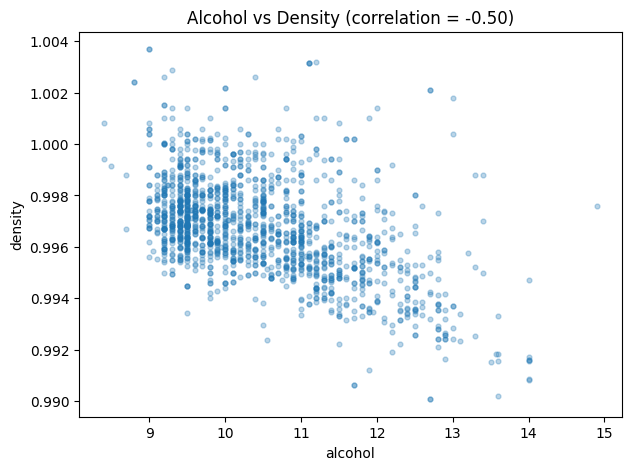

In [20]:
# Scatter plot of the two features (negative covariance = downward trend)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, s=12)
plt.xlabel("alcohol"); plt.ylabel("density")
plt.title(f"Alcohol vs Density (correlation = {corr:.2f})")
plt.show()

**Interpretation**
- **Largest eigenvalue (about 1.1356):** its eigenvector, roughly (1.0000, -0.0009), points almost entirely along the **alcohol** axis. This is the direction of greatest variance, and it contains about 99.9998 % of the total variance.
- **Second eigenvalue (about 0.0000027):** its eigenvector, roughly (0.0009, 1.0000), is perpendicular to the first and lies almost entirely along the **density** axis. It captures a negligible share of the variance.
- This happens because the two features are on very different scales, so the raw covariance matrix is dominated by alcohol. The eigen decomposition reflects the units, not just the structure of the relationship. To compare the features fairly, standardise them first (use `np.corrcoef`, or z-score the columns); this would give eigenvalues of about 1.5 and 0.5, with eigenvectors along the diagonals.

In [21]:
# Same decomposition on standardised features, to show the effect of scale
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
vals_z, vecs_z = np.linalg.eig(np.cov(Z.T))
vals_z, vecs_z = vals_z.real, vecs_z.real
idx = np.argsort(vals_z)[::-1]
print("Standardised eigenvalues:", vals_z[idx])
print("Standardised eigenvectors (columns):\n", vecs_z[:, idx])

Standardised eigenvalues: [1.49617977 0.50382023]
Standardised eigenvectors (columns):
 [[ 0.70710678  0.70710678]
 [-0.70710678  0.70710678]]


## 5. Most common wine quality and the distribution of scores

In [22]:
counts = df["quality"].value_counts().sort_index()
probs = (counts / len(df)).round(4)
summary = pd.DataFrame({"Count": counts, "Probability": probs, "Percentage (%)": (probs*100).round(2)})
print("Most common quality:", df["quality"].mode()[0])
summary

Most common quality: 5


,Count,Probability,Percentage (%)
quality,,,
3,10,0.0063,0.63
4,53,0.0331,3.31
5,681,0.4259,42.59
6,638,0.3990,39.90
7,199,0.1245,12.45
8,18,0.0113,1.13


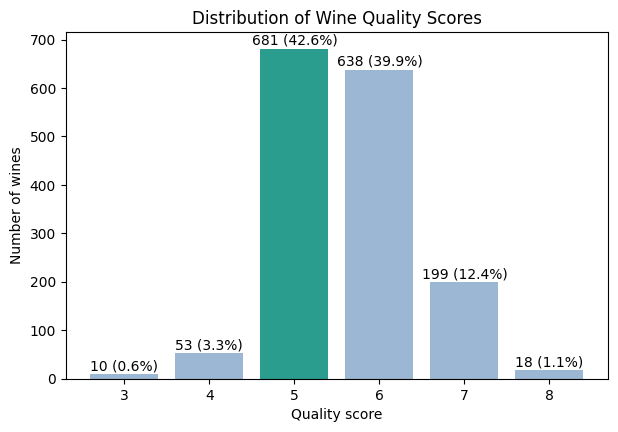

Mean = 5.64, Median = 6, Std = 0.81, Skewness = 0.22
P(quality is 5 or 6) = 0.825
P(quality >= 7)      = 0.136


In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#2a9d8f" if q == df["quality"].mode()[0] else "#9bb7d4" for q in counts.index]
ax.bar(counts.index.astype(str), counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f"{v} ({v/len(df)*100:.1f}%)", ha="center")
ax.set_xlabel("Quality score"); ax.set_ylabel("Number of wines")
ax.set_title("Distribution of Wine Quality Scores")
plt.show()

print("Mean = %.2f, Median = %.0f, Std = %.2f, Skewness = %.2f" % (
    df["quality"].mean(), df["quality"].median(), df["quality"].std(), df["quality"].skew()))
print("P(quality is 5 or 6) = %.3f" % df["quality"].isin([5, 6]).mean())
print("P(quality >= 7)      = %.3f" % (df["quality"] >= 7).mean())

**Interpretation**
- **Quality 5 is the most common** (681 wines, about 42.6 %), closely followed by quality 6 (638 wines, about 39.9 %).
- Together, qualities 5 and 6 make up about **82.5 %** of all wines, so the distribution is concentrated around the middle (mean about 5.64).
- The extremes are rare: only 10 wines (0.6 %) score 3 and 18 wines (1.1 %) score 8, and no wine scores below 3 or above 8 even though the scale runs 0-10.
- The distribution is roughly bell-shaped and slightly skewed to the right (the tail towards high scores is a bit longer), so excellent wines are uncommon.
- In probability terms, a randomly chosen wine has about a 0.43 chance of being quality 5 and about a 0.14 chance of being quality 7 or higher.
- The classes are **imbalanced**: a model predicting quality would see many examples of 5 and 6 and very few of 3, 4 and 8.